# 16 图神经网络：从邻居求和写到 GCN

一个节点自己的观测可能很嘈杂，而与它相连的节点提供了另一份线索。本课后面的分类数据就这样生成：每个节点有四个带噪声的数，同组节点之间更容易连边。模型需要学习怎样结合节点自身与邻居的信息。

## 1 一行邻接矩阵，列出一个点接收谁的消息

图包含 N 个节点。无向图的邻接矩阵 A 为 `(N,N)`，$A_{ij}=1$ 表示节点 i 与 j 相连。第 i 行列出 i 的邻居。
节点特征矩阵 X 为 `(N,F)`，每行 F 个实数。先把图缩到四个节点：0—1—2，节点 3 单独存在。节点 1 的两个邻居各有一行特征，矩阵乘法 `A @ X` 会按 A 中的 1 取出这些行，再相加。

In [1]:
from support import ROOT, check, show, style

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
torch.set_num_threads(1)
torch.manual_seed(16)
style()

In [3]:
A = np.array([[0.,1.,0.,0.], [1.,0.,1.,0.], [0.,1.,0.,0.], [0.,0.,0.,0.]])
X = np.array([[1.,0.], [0.,2.], [3.,1.], [2.,2.]])
print('neighbors of node 1:', np.flatnonzero(A[1]))
print('their features:', X[A[1].astype(bool)])
print('A @ X:', A @ X)

neighbors of node 1: [0 2]
their features: [[1. 0.]
 [3. 1.]]
A @ X: [[0. 2.]
 [4. 1.]
 [0. 2.]
 [0. 0.]]


### 练习 g01：把邻居求和写成一行

节点 1 接收节点 0、2 的特征。取出两行并相加，再用邻接矩阵乘法核对。

In [4]:
ex_g01_X = np.array([[1.,0.], [0.,2.], [3.,1.], [2.,2.]])
ex_g01_sum = None  # TODO
ex_g01_degree = None  # TODO: 节点 1 的邻居数

In [5]:
# 填写上一格后，运行检查。
check('邻居特征和', ex_g01_sum, [4.,1.])
check('邻居数', ex_g01_degree, 2)

待填写：邻居特征和
待填写：邻居数


<details>
<summary>提示</summary>

整数行索引 [0,2] 取两个邻居；沿 axis=0 对这两行求和。

</details>

<details>
<summary>参考答案</summary>

```python
ex_g01_X = np.array([[1.,0.], [0.,2.], [3.,1.], [2.,2.]])
ex_g01_sum = ex_g01_X[[0, 2]].sum(axis=0)
ex_g01_degree = 2
```

</details>

节点 1 收到 [1,0] 与 [3,1]，相加为 [4,1]。下图节点内写原始特征，每条青色箭头对应一份发往节点 1 的向量。图中的加号与 `A @ X` 第 1 行做的是同一次计算。

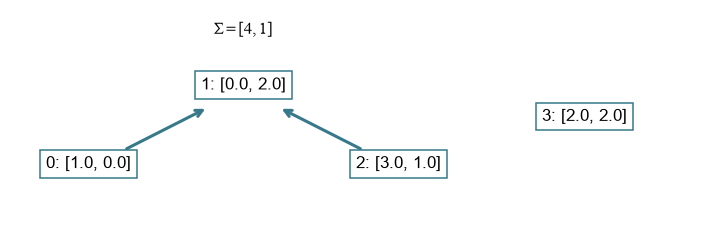

In [6]:
small_pos = np.array([[0.,0.], [1.,.5], [2.,0.], [3.2,.3]])
fig, ax = plt.subplots(figsize=(8, 2.6))
for j in [0, 2]:
    ax.annotate('', small_pos[1], small_pos[j], arrowprops=dict(arrowstyle='->', color='#37798A', lw=2, shrinkA=28, shrinkB=28))
for j, point in enumerate(small_pos):
    ax.text(*point, f'{j}: {X[j].tolist()}', ha='center', bbox=dict(fc='white', ec='#37798A'))
ax.text(1., .85, r'$\Sigma=[4,1]$', ha='center')
ax.set(xlim=(-.5,3.9), ylim=(-.4,1.)); ax.axis('off')
show(fig)

## 2 自环与度数归一化

刚才节点 1 的聚合结果只包含邻居，原有的 [0,2] 没有参加相加。增加单位阵 I，就给每个节点加上一条发给自己的消息：$\widetilde A=A+I$。

邻居越多，直接求和包含的项也越多。GCN 在每条消息上乘一个由两端度数决定的系数。新度数 $\widetilde d_i=\sum_j\widetilde A_{ij}$，对称归一化权重为
$$\widehat A_{ij}=\frac{\widetilde A_{ij}}{\sqrt{\widetilde d_i\widetilde d_j}},\qquad
\widehat A=\widetilde D^{-1/2}\widetilde A\widetilde D^{-1/2}.$$
$\widetilde D$ 是把度数放在对角线上的矩阵。左乘 $\widetilde D^{-1/2}$ 按接收端缩放行，右乘它按发送端缩放列；所以边 i、j 的权重同时包含两端度数。

In [7]:
A_self = A + np.eye(len(A))
degree = A_self.sum(axis=1)
inverse_sqrt = degree ** -.5
A_hat = inverse_sqrt[:, None] * A_self * inverse_sqrt[None, :]
print('degrees:', degree)
print('normalized adjacency:', np.round(A_hat, 4))
print('aggregated features:', A_hat @ X)

degrees: [2. 3. 2. 1.]
normalized adjacency: [[0.5    0.4082 0.     0.    ]
 [0.4082 0.3333 0.4082 0.    ]
 [0.     0.4082 0.5    0.    ]
 [0.     0.     0.     1.    ]]
aggregated features: [[0.5        0.81649658]
 [1.63299316 1.07491496]
 [1.5        1.31649658]
 [2.         2.        ]]


### 练习 g02：孤立节点加入自环以后

节点 3 原来没有邻居。求加自环后的度数，以及聚合后它自己的特征。

In [8]:
ex_g02_degree = None  # TODO
ex_g02_feature = None  # TODO
ex_g02_node = 3

In [9]:
# 填写上一格后，运行检查。
check('加自环后的度数', ex_g02_degree, 1.)
check('保留的节点特征', ex_g02_feature, [2.,2.])

待填写：加自环后的度数
待填写：保留的节点特征


<details>
<summary>提示</summary>

自环给它一条自己到自己的边，权重为 1/√(1×1)。

</details>

<details>
<summary>参考答案</summary>

```python
ex_g02_node = 3
ex_g02_degree = (A+np.eye(4)).sum(axis=1)[ex_g02_node]
ex_g02_feature = (A_hat @ X)[ex_g02_node]
```

</details>

节点 1 的加自环度数为 3，节点 0、2 的为 2。因此它收到的三个加权向量是
$$\frac{X_0}{\sqrt6},\quad\frac{X_1}{3},\quad\frac{X_2}{\sqrt6}.$$
两条邻居消息的系数为 $1/\sqrt{3\times2}$，自己的消息为 $1/\sqrt{3\times3}$。把这三项逐坐标相加，再对照 `A_hat @ X` 的第 1 行。若改用行归一化平均，三条消息的系数才都是 1/3。

### 练习 g03：手写一行归一化聚合

按三个向量的权重计算节点 1 的新特征。

In [10]:
ex_g03_messages = None  # TODO: 相加三个加权向量
ex_g03_scale = np.sqrt(6.)
ex_g03_self_degree = 3.

In [11]:
# 填写上一格后，运行检查。
check('节点 1 的归一化消息', ex_g03_messages, [4/np.sqrt(6), 2/3+1/np.sqrt(6)])

待填写：节点 1 的归一化消息


<details>
<summary>提示</summary>

X[0]/√6 + X[1]/3 + X[2]/√6。

</details>

<details>
<summary>参考答案</summary>

```python
ex_g03_scale = np.sqrt(6.)
ex_g03_self_degree = 3.
ex_g03_messages = X[0]/ex_g03_scale + X[1]/ex_g03_self_degree + X[2]/ex_g03_scale
```

</details>

## 3 所有节点共享同一个线性映射

聚合规定了信息从哪里来，还需要学习怎样处理这些特征。W 的形状为 `(F,H)`，把每个节点的 F 维特征映射为 H 维。同一层的所有节点使用同一组 W；某种特征组合有用时，这条处理规则可以用于图中任何节点。

把第 l 层全体节点的表示记作 $H^{(l)}$，初值 $H^{(0)}=X$：
$$H^{(l+1)}=\operatorname{ReLU}(\widehat A H^{(l)}W^{(l)}).$$
右侧先用 W 改变特征通道，再用 $\widehat A$ 混合节点；这两个线性步骤也可交换结合顺序。ReLU 最后逐项把负数置零。下一格保留三个中间张量，能逐行核对一次完整传播。

In [12]:
W = np.array([[1., -.5], [.5, 1.]])
transformed = X @ W
aggregated = A_hat @ transformed
H = np.maximum(aggregated, 0.)
print('shared transform:', transformed)
print('after aggregation and ReLU:', H)

shared transform: [[ 1.  -0.5]
 [ 1.   2. ]
 [ 3.5 -0.5]
 [ 3.   1. ]]
after aggregation and ReLU: [[0.90824829 0.56649658]
 [2.17045064 0.25841838]
 [2.15824829 0.56649658]
 [3.         1.        ]]


## 4 换一套节点编号，结果也只换编号

给节点重新编号，连接关系和特征所描述的对象仍然相同。一个节点原先得到的结果，也应跟着它移动到新的行。

置换矩阵 P 每行每列恰有一个 1，表示这种重排。重排输入 $X'=PX$、图 $A'=PAP^\top$ 后，GCN 输出应为 $H'=PH$，这叫置换等变。A 的行表示接收者，列表示发送者，因此两个轴都要同步重排。下面保持 W 不变，用同一组特征和边检查这个关系。

In [13]:
permutation = np.array([2, 0, 3, 1])
P = np.eye(4)[permutation]
permuted_features = P @ X
permuted_graph = P @ A_hat @ P.T
permuted_output = np.maximum(permuted_graph @ permuted_features @ W, 0.)
check('节点重排等变', permuted_output, P @ H)

通过：节点重排等变


### 练习 g04：只重排特征会发生什么

正确重排需要同步处理邻接矩阵的两个轴。构造 A_hat[np.ix_(p,p)] 并计算新输出。

In [14]:
ex_g04_p = np.array([3, 2, 1, 0])
ex_g04_A = None  # TODO
ex_g04_output = None  # TODO

In [15]:
# 填写上一格后，运行检查。
check('同步重排的输出', ex_g04_output, H[[3,2,1,0]])

待填写：同步重排的输出


<details>
<summary>提示</summary>

新特征是 X[p]；A 的新第 i、j 项来自旧第 p[i]、p[j] 项。

</details>

<details>
<summary>参考答案</summary>

```python
ex_g04_p = np.array([3, 2, 1, 0])
ex_g04_A = A_hat[np.ix_(ex_g04_p, ex_g04_p)]
ex_g04_output = np.maximum(ex_g04_A @ X[ex_g04_p] @ W, 0.)
```

</details>

## 5 一张图里的节点分类任务

现在把小图中的运算用于开头的分类任务。生成 120 个节点，两组各 60 个。同组连边概率 .16，跨组 .015；四维特征为噪声，其中第 0 维带较弱的组别偏移。单看一个节点的特征，组别信号容易被噪声盖住；沿边收集邻居特征，可以利用同组更常相连的结构。

组号是待预测标签。每组取 10 个训练节点、10 个验证节点，其余用于测试，共有 20 个训练标签。前向使用整张已观察到的图与节点特征；训练损失只读取这 20 个标签。这是同一图上的传导式节点分类。

In [16]:
rng = np.random.default_rng(161)
labels_np = np.repeat([0, 1], 60)
probabilities = np.where(labels_np[:, None] == labels_np[None, :], .16, .015)
upper = np.triu(rng.random((120,120)) < probabilities, k=1)
graph_np = (upper | upper.T).astype(float)
features_np = rng.normal(size=(120, 4))
features_np[:, 0] += .35 * (2*labels_np-1)

In [17]:
train_mask = torch.zeros(120, dtype=torch.bool)
val_mask = torch.zeros_like(train_mask)
for group in [0, 1]:
    ids = rng.permutation(np.flatnonzero(labels_np == group))
    train_mask[ids[:10]] = True
    val_mask[ids[10:20]] = True
test_mask = ~(train_mask | val_mask)
print('train / validation / test:', train_mask.sum().item(), val_mask.sum().item(), test_mask.sum().item())

train / validation / test: 20 20 80


In [18]:
graph_self = graph_np + np.eye(120)
graph_scale = graph_self.sum(axis=1) ** -.5
graph_tensor = torch.tensor(graph_scale[:,None]*graph_self*graph_scale[None,:], dtype=torch.float32)
features = torch.tensor(features_np, dtype=torch.float32)
labels = torch.tensor(labels_np, dtype=torch.long)
print('A_hat / X / labels:', graph_tensor.shape, features.shape, labels.shape)

A_hat / X / labels: torch.Size([120, 120]) torch.Size([120, 4]) torch.Size([120])


第一层把四维输入变成 12 维隐藏表示，并混合一跳邻居；第二层再次聚合，所以输出也能受到两跳范围内特征的影响。最后每个节点有两个类别分数，交叉熵内部计算 log-softmax。两层都使用刚才手算过的 `A_hat @ 特征`。

In [19]:
class ManualGCN(nn.Module):
    def __init__(self):
        super().__init__()
        self.first = nn.Linear(4, 12, bias=False)
        self.second = nn.Linear(12, 2, bias=False)
    def forward(self, X, A_hat):
        hidden = torch.relu(A_hat @ self.first(X))
        return A_hat @ self.second(hidden)

### 练习 g05：标签只从训练掩码进入损失

4 个节点的 logits 全为 0，标签为 [0,1,1,0]，仅前两个节点参加交叉熵。求 logits 梯度。

In [20]:
ex_g05_logits = torch.zeros(4, 2, requires_grad=True)
ex_g05_labels = torch.tensor([0,1,1,0])
ex_g05_mask = torch.tensor([True,True,False,False])
ex_g05_grad = None  # TODO

In [21]:
# 填写上一格后，运行检查。
check('掩码后的分数梯度', ex_g05_grad, [[-.25,.25],[.25,-.25],[0.,0.],[0.,0.]])

待填写：掩码后的分数梯度


<details>
<summary>提示</summary>

计算 cross_entropy(logits[mask],labels[mask])，再用 autograd.grad。两训练节点的损失取均值。

</details>

<details>
<summary>参考答案</summary>

```python
ex_g05_logits = torch.zeros(4, 2, requires_grad=True)
ex_g05_labels = torch.tensor([0,1,1,0])
ex_g05_mask = torch.tensor([True,True,False,False])
ex_g05_loss = F.cross_entropy(ex_g05_logits[ex_g05_mask], ex_g05_labels[ex_g05_mask])
ex_g05_grad = torch.autograd.grad(ex_g05_loss, ex_g05_logits)[0]
```

</details>

这个练习中，后两个节点的分数梯度为零，因为它们没有直接参加损失。在完整 GCN 中，这些节点的特征仍能沿边影响训练节点的分数，进而影响共享参数的梯度。标签由 `train_mask` 选入损失，消息由图中的边传递，是两条不同的信息通路。下面训练 180 轮，最后分别读取验证与测试节点的准确率。

In [22]:
torch.manual_seed(162)
model = ManualGCN()
optimizer = torch.optim.Adam(model.parameters(), lr=.03, weight_decay=5e-4)
losses = []
for epoch in range(180):
    optimizer.zero_grad()
    logits = model(features, graph_tensor)
    loss = F.cross_entropy(logits[train_mask], labels[train_mask])
    loss.backward(); optimizer.step()
    losses.append(loss.item())

In [23]:
with torch.no_grad():
    predicted = model(features, graph_tensor).argmax(dim=1)
val_accuracy = (predicted[val_mask] == labels[val_mask]).float().mean().item()
test_accuracy = (predicted[test_mask] == labels[test_mask]).float().mean().item()
print('validation / test accuracy:', val_accuracy, test_accuracy)
angles = np.linspace(0, 2*np.pi, 120, endpoint=False)
positions = np.column_stack([np.cos(angles), np.sin(angles)])

validation / test accuracy: 0.949999988079071 0.949999988079071


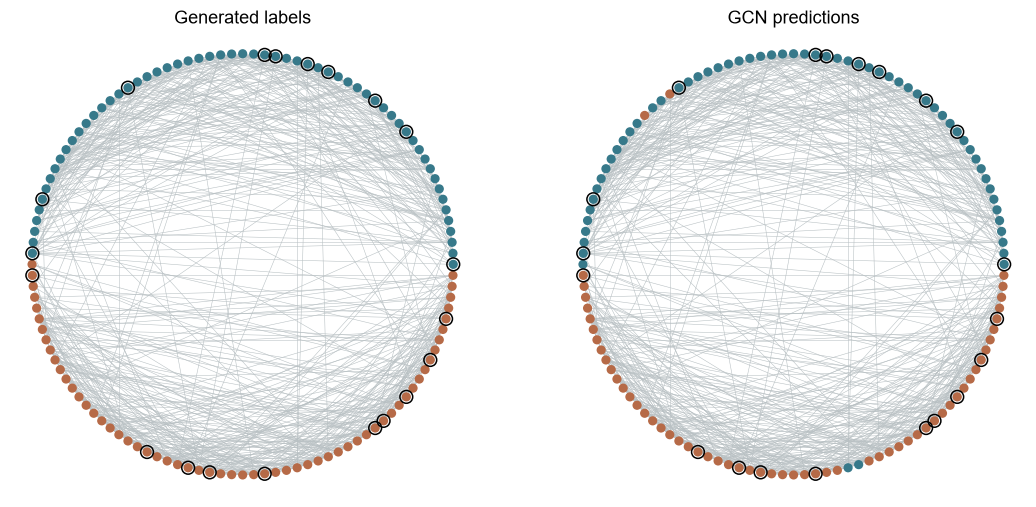

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), layout='constrained')
for ax, coloring, title in zip(axes, [labels_np, predicted.numpy()], ['Generated labels', 'GCN predictions']):
    for left, right in np.argwhere(np.triu(graph_np, 1)):
        ax.plot(positions[[left,right],0], positions[[left,right],1], color='#B8C0C3', lw=.35, zorder=1)
    ax.scatter(*positions.T, c=np.array(['#37798A','#B66A47'])[coloring], s=25, zorder=2)
    ax.scatter(*positions[train_mask.numpy()].T, facecolors='none', edgecolors='black', s=70, zorder=3)
    ax.set_title(title); ax.set_aspect('equal'); ax.axis('off')
show(fig)

左图颜色来自生成标签，右图颜色来自模型预测；黑色圆圈标出提供训练标签的节点。对照同一位置的两种颜色，可以看到预测错误落在哪些节点，再沿边查看它们接收的信息。

## 6 只改变传播次数，观察过平滑

邻居聚合让一个节点获得更多信息，反复聚合也会不断混合原有差异。另建一个 24 节点环，每节点连接左右邻居，加自环后度数均为 3。固定初始特征与 W=I，反复做 $H_{k+1}=\widehat A H_k$，只考察传播次数的作用。

在这个规则环上，每一步都将自己与左右邻居取平均。传播次数增加后，各节点特征趋向同一个全图均值。左图用节点间方差量化差异，右图沿节点编号画同一特征通道：起伏逐渐变平，就对应可区分信息的减少。

In [25]:
ring = np.eye(24)
for node in range(24):
    ring[node, (node-1)%24] = ring[node, (node+1)%24] = 1.
ring /= 3.
initial_features = np.random.default_rng(163).normal(size=(24, 3))
propagation = [initial_features]
for depth in range(64):
    propagation.append(ring @ propagation[-1])
variances = [np.var(value, axis=0).mean() for value in propagation]

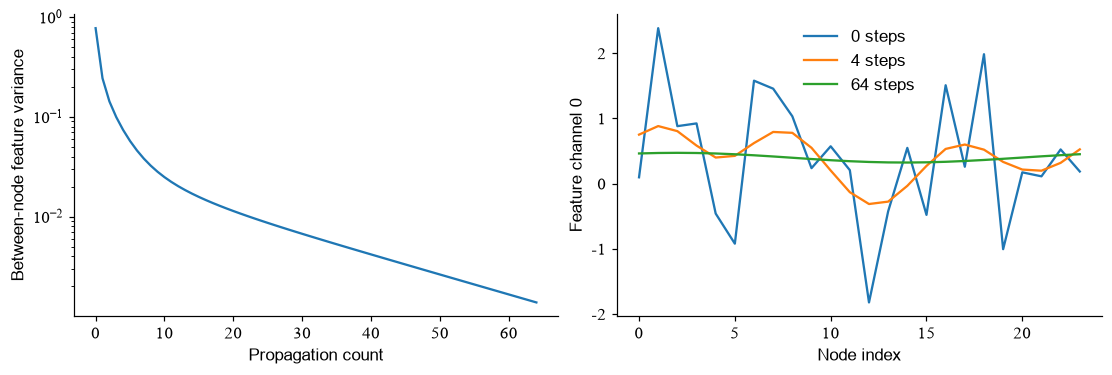

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), layout='constrained')
axes[0].semilogy(variances); axes[0].set(xlabel='Propagation count', ylabel='Between-node feature variance')
for depth in [0, 4, 64]:
    axes[1].plot(propagation[depth][:,0], label=f'{depth} steps')
axes[1].set(xlabel='Node index', ylabel='Feature channel 0')
axes[1].legend(frameon=False)
show(fig)

### 练习 g06：检查局部平均保留什么

对规则环做 20 次传播，比较每个特征通道在节点上的平均值是否改变。

In [27]:
ex_g06_H = initial_features.copy()
ex_g06_mean = None  # TODO: 传播后对节点轴求均值
ex_g06_steps = 20

In [28]:
# 填写上一格后，运行检查。
check('保留的全图通道均值', ex_g06_mean, initial_features.mean(axis=0))

待填写：保留的全图通道均值


<details>
<summary>提示</summary>

循环 H=ring@H；mean(axis=0) 沿节点轴平均。规则环矩阵的行和与列和都是 1。

</details>

<details>
<summary>参考答案</summary>

```python
ex_g06_H = initial_features.copy()
ex_g06_steps = 20
for ex_g06_depth in range(ex_g06_steps):
    ex_g06_H = ring @ ex_g06_H
ex_g06_mean = ex_g06_H.mean(axis=0)
```

</details>

环上的各节点逐渐接近，但每个特征通道的全图均值保留下来。上面的检查把这两件事分开：传播可以保留总体平均，同时抹去节点之间的差异。实际分类需要的是后者能够区分组别。

回到分类图，只把跨组连边概率从 .015 改到 .08，保留组内概率、节点特征、划分和优化设置。跨组消息变多后，比较 GCN 与将 A_hat 换成 I 的同宽模型，记录训练误差、测试误差和节点表示距离。重复至少五个图随机种子，检验更频繁的跨组混合是否削弱了这份数据中的邻域线索。

## 带着问题读原文

[Kipf 与 Welling：Semi-Supervised Classification with GCNs](https://arxiv.org/abs/1609.02907)

对应原文传播式逐项标出本课的自环、度数、X 和 W。为什么没有标签的节点仍可参加前向？附录深度实验中，层数增加同时改变了哪些变量？怎样用本课的规则环控制实验把传播效应单独取出来？